# 6 · Stability trade studies

Neutral point, the CG's effect on the short period, and the lateral spiral/dutch-roll trade.
Lesson: [06](../docs/lessons/06-stability-trade-studies.md) ·
Theory: [trade studies](../docs/trade_studies.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from flightdyn import plotting as P

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and reference aircraft
from reference_aircraft import b747, b747_condition, navion, navion_condition
from flightdyn.trade_studies import lateral_map, longitudinal_point, neutral_point_shift

In [2]:
ac, c = b747(2), b747_condition(2)
hn = neutral_point_shift(ac)
print(f"neutral point {0.25 + hn:.3f} MAC, static margin {100 * hn:.1f} % MAC")
for h in (0.10, 0.20, 0.30, 0.40):
    p = longitudinal_point(ac, c["V"], c["h"], h - 0.25)
    sp = p.modes["short_period"]
    print(f"CG {h:.2f}: margin {100 * p.static_margin:5.1f} %, short period "
          f"wn {sp.wn:.3f} rad/s, zeta {sp.zeta:.3f}, trim elevator {np.degrees(p.de_trim):+.1f} deg")

neutral point 0.470 MAC, static margin 22.0 % MAC
CG 0.10: margin  37.0 %, short period wn 1.095 rad/s, zeta 0.525, trim elevator -7.4 deg
CG 0.20: margin  27.0 %, short period wn 0.974 rad/s, zeta 0.587, trim elevator -2.4 deg
CG 0.30: margin  17.0 %, short period wn 0.837 rad/s, zeta 0.682, trim elevator +2.6 deg
CG 0.40: margin   7.0 %, short period wn 0.666 rad/s, zeta 0.852, trim elevator +7.5 deg


## Spiral and dutch roll against dihedral effect and directional stiffness

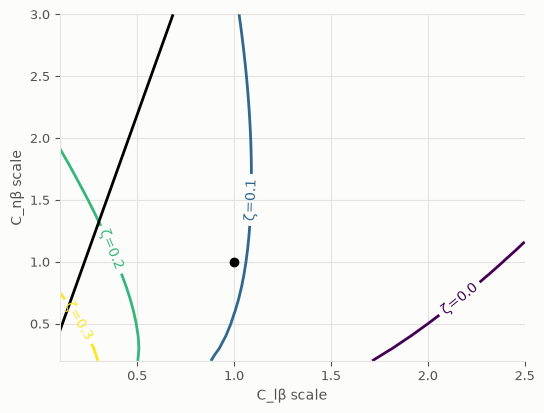

In [3]:
k_lb, k_nb = np.linspace(0.1, 2.5, 25), np.linspace(0.2, 3.0, 29)
spiral, zeta, crit = lateral_map(ac, c["V"], c["h"], k_lb, k_nb)
fig, ax = plt.subplots(figsize=(6, 4.5))
cs = ax.contour(k_lb, k_nb, zeta, levels=[0.0, 0.1, 0.2, 0.3])
ax.clabel(cs, fmt="ζ=%.1f")
ax.contour(k_lb, k_nb, crit, levels=[0.0], colors="k")
ax.plot(1, 1, "ko")
ax.set_xlabel("C_lβ scale")
ax.set_ylabel("C_nβ scale");